# Reliability and Originality Classification in MM-Health — Full Pipeline

## Project Aim

This project evaluates NLP models for two dataset-defined text-classification tasks in MM-Health:

- **Reliability classification:** distinguishing reliable from unreliable human-written health articles.
- **Originality classification:** distinguishing human-written from AI-generated articles.

The aim is to compare classical and transformer-based models and assess whether strong benchmark performance remains robust under changes in authorship, source and AI generator. Additional analyses examine potential formatting, stylometric and lexical shortcuts that may contribute to model predictions.

## 1. Package Installation and Imports

In [1]:
!pip -q install -U transformers datasets accelerate scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 57.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 72.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 15.2 MB/s eta 0:00:00


In [18]:
# Standard library
import inspect
import json
import os
import random
import re

# Core libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# Data and Hugging Face
from datasets import Dataset
from huggingface_hub import hf_hub_download
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
)

# Statistics and evaluation
from scipy.stats import chi2, wilcoxon
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight

# Classical models and features
from sklearn.feature_extraction.text import (
    ENGLISH_STOP_WORDS,
    TfidfVectorizer,
)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

## 2. Environment Setup and Configuration

### Saved Model Weights

The fine-tuned model weights used for the standard transformer experiments are provided separately to avoid repeating computationally expensive training runs.

**Download the saved model folder here:**  
[MM-Health Saved Model Weights](https://drive.google.com/drive/folders/1IBlyv8aj1Za_4O-Ok6Ga1MMQhcBbabpm?usp=drive_link)

To reuse the saved models in Google Colab:

1. Download the `mmhealth_models` folder from the link above.
2. Upload the folder to the root of your Google Drive (`MyDrive`).
3. Mount Google Drive using the cell below.
4. If the folder is stored elsewhere, update the model directory path accordingly.

The submitted notebook is fully executed. The saved weights are provided so that the standard trained transformer models can be reloaded without retraining.

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = "/content/drive/MyDrive"
except ImportError:
    DRIVE_ROOT = "."

# ============================ CONFIG ============================

TASKS = ["reliability", "originality"]

SEED = 42
MAX_LENGTH = 256
BATCH_SIZE = 16
EPOCHS = 3
LR = 2e-5

# Reuse saved standard model weights when available.
RETRAIN_IF_EXISTS = False
SAVE_MODELS = True

# Generalisation experiments
RUN_CROSS_GENERATOR = True   # originality only
RUN_CROSS_SOURCE = True      # reliability only
CROSS_MODEL = "roberta"
CROSS_EPOCHS = 3

MODELS = {
    "bert": "bert-base-uncased",
    "roberta": "roberta-base",
    "pubmedbert": "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract",
}

OUTPUT_DIR = os.path.join(DRIVE_ROOT, "mmhealth_models")

# Check whether the supplied saved-model folder is available.
if not os.path.isdir(OUTPUT_DIR):
    raise FileNotFoundError(
        f"Saved model folder not found: {OUTPUT_DIR}\n"
        "Download the supplied 'mmhealth_models' folder and place it "
        "in the root of MyDrive before running the model cells."
    )

# ===============================================================

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print(
    "Device:", DEVICE,
    "| Tasks:", TASKS,
    "| Model directory:", OUTPUT_DIR,
)

Mounted at /content/drive
Device: cuda | Tasks: ['reliability', 'originality'] | Model directory: /content/drive/MyDrive/mmhealth_models


## 3. MM-Health Data Loading and Preparation

In [4]:
SPLIT_KEYS = {"train", "test", "val", "validation"}
RELIABILITY = {"1": "reliable", "0": "unreliable"}


def iter_articles(node, split=None):
    """Yield each article with its inherited train, validation or test split."""
    if isinstance(node, dict):
        if "text" in node and "label" in node:
            yield split, node
        else:
            for key, child in node.items():
                child_split = (
                    key if split is None and key.lower() in SPLIT_KEYS else split
                )
                yield from iter_articles(child, child_split)

    elif isinstance(node, list):
        for child in node:
            yield from iter_articles(child, split)


# Load the official MM-Health split file
path = hf_hub_download(
    "zzha6204/MM-Health",
    "train_test_splited_data.json",
    repo_type="dataset",
)

with open(path, encoding="utf-8") as f:
    raw = json.load(f)


# Flatten to one row per text variant
rows = []

for split, article in iter_articles(raw):
    uid = f"{article['source']}__{article['id']}"
    reliability = RELIABILITY[str(article["label"]).strip()]

    for generator, text in article["text"].items():
        text = re.sub(r"\s+", " ", str(text)).strip()

        if not text:
            continue

        rows.append({
            "uid": uid,
            "split": split,
            "source": article["source"],
            "generator": generator,
            "origin": "human" if generator.lower() in ("original", "human") else "ai",
            "reliability": reliability,
            "text": text,
            "n_words": len(text.split()),
        })

df = pd.DataFrame(rows)


# Sanity checks
print("rows:", len(df))
print("split:", df["split"].value_counts(dropna=False).to_dict())
print("reliability:", df["reliability"].value_counts().to_dict())
print("generators:", df["generator"].unique().tolist())
print("sources:", df["source"].unique().tolist())

df.head()

train_test_splited_data.json: reconstructing file:   0%|          |  0.00B /  135MB            

train_test_splited_data.json: downloading bytes:           |  0.00B            

rows: 34656
split: {'train': 24924, 'test': 6954, 'val': 2778}
reliability: {'reliable': 27900, 'unreliable': 6756}
generators: ['original', 'llama3.1', 'qwen2.5', 'chatglm4', 'gemma2', 'mistral']
sources: ['Med-MMHL', 'MM-COVID19', 'ReCOVery', 'MMCoVar']


,uid,split,source,generator,origin,reliability,text,n_words
0,Med-MMHL__1044,train,Med-MMHL,original,human,reliable,The National Institutes of Health has started ...,616
1,Med-MMHL__1044,train,Med-MMHL,llama3.1,ai,reliable,**NIH Launches Groundbreaking Study to Evaluat...,482
2,Med-MMHL__1044,train,Med-MMHL,qwen2.5,ai,reliable,### NIH Launches Phase 1/2 Clinical Trial for ...,532
3,Med-MMHL__1044,train,Med-MMHL,chatglm4,ai,reliable,# Exploring the Future of Immune Defense: NIH’...,496
4,Med-MMHL__1044,train,Med-MMHL,gemma2,ai,reliable,## NIH Launches Clinical Trial Exploring COVID...,284


## 4. Shared Helper Functions

This section defines reusable functions for data splitting, evaluation, baseline models, and transformer training/loading.

Article identifiers are used to keep related text variants grouped during splitting, reducing the risk of article-level data leakage. Model results are also recorded through a shared evaluation function to ensure consistent metric reporting across experiments.

In [5]:
# ---------- text normalization ----------
def clean_text(t):
    """Collapse repeated whitespace and remove outer whitespace."""
    return re.sub(r"\s+", " ", str(t)).strip()

# ---------- task framing ----------
def make_task_frame(df, task):
    """reliability: human articles only (reliable/unreliable).
       originality: all six variants (human/ai)."""
    if task == "reliability":
        work, target, label_names = df[df["origin"] == "human"].copy(), "reliability", ["reliable", "unreliable"]
    elif task == "originality":
        work, target, label_names = df.copy(), "origin", ["human", "ai"]
    else:
        raise ValueError(f"Unknown task: {task}")
    label2id = {n: i for i, n in enumerate(label_names)}
    work["label"] = work[target].map(label2id)
    return work.reset_index(drop=True), label_names, label2id

# ---------- splitting ----------
def split_frame(work):
    """Use the dataset's official train/val/test tags. They are assigned per article,
    so every variant of an article shares one tag and no article spans splits."""
    parts = {s: work[work["split"] == s].reset_index(drop=True) for s in ("train", "val", "test")}
    empty = [s for s, d in parts.items() if len(d) == 0]
    if empty:
        raise ValueError(f"Missing official split(s): {empty}")
    return parts["train"], parts["val"], parts["test"]

def carve_val(pool, frac=0.15, seed=SEED):
    """Article-grouped validation split used for cross-source evaluation."""
    groups = pool["uid"].unique()
    np.random.RandomState(seed).shuffle(groups)
    val_groups = set(groups[:int(frac * len(groups))])
    in_val = pool["uid"].isin(val_groups)
    return pool[~in_val].reset_index(drop=True), pool[in_val].reset_index(drop=True)

def class_weights_for(train_df):
    y = train_df["label"].values
    return torch.tensor(compute_class_weight("balanced", classes=np.unique(y), y=y), dtype=torch.float)

# ---------- evaluation sink ----------
def log_result(task, model, y_true, y_pred, label_names, plot=True):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    p, r, wf1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    print(f"\n=== {task} | {model} ===")
    print(classification_report(y_true, y_pred, target_names=label_names, zero_division=0))
    if plot:
        ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=label_names
                               ).plot(values_format="d", cmap="Blues"); plt.title(f"{task} | {model}"); plt.show()
    RESULTS.append({"task": task, "model": model, "accuracy": accuracy_score(y_true, y_pred),
                    "precision": p, "recall": r, "weighted_f1": wf1,
                    "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0)})
    PREDS[(task, model)] = (y_true, y_pred)

# ---------- classical baselines ----------
def run_baselines(task, train_df, test_df, label_names):
    models = {"TFIDF+LogReg":   LogisticRegression(max_iter=2000, class_weight="balanced"),
              "TFIDF+LinearSVM": LinearSVC(class_weight="balanced")}
    for name, clf in models.items():
        pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=30000)),
                         ("clf", clf)]).fit(train_df["text"], train_df["label"])
        log_result(task, name, test_df["label"].values, pipe.predict(test_df["text"]), label_names, plot=False)

# ---------- transformer training ----------
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro", zero_division=0)}

class WeightedTrainer(Trainer):
    def __init__(self, class_weights=None, **kw):
        super().__init__(**kw); self.class_weights = class_weights
    def compute_loss(self, model, inputs, return_outputs=False, **kw):
        labels = inputs.pop("labels"); outputs = model(**inputs)
        loss = nn.CrossEntropyLoss(weight=self.class_weights.to(outputs.logits.device))(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

# Auto-detect API names so the cell works across transformers versions
_EVAL_KEY = "eval_strategy" if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters else "evaluation_strategy"
_PROC_KEY = "processing_class" if "processing_class" in inspect.signature(Trainer.__init__).parameters else "tokenizer"

def _make_ds(split_df, tok):
    ds = Dataset.from_pandas(split_df[["text", "label"]], preserve_index=False)
    ds = ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LENGTH), batched=True)
    return ds.remove_columns([c for c in ds.column_names if c not in ("input_ids", "attention_mask", "label")])

def train_or_load(task, key, model_name, train_df, val_df, test_df, label_names, label2id,
                  class_weights, retrain=False, save=True, epochs=EPOCHS, save_name=None, seed=SEED):
    save_name = save_name or f"{task}_{key}"
    save_dir  = os.path.join(OUTPUT_DIR, save_name)
    set_seed(seed)

    _has_weights = any(os.path.isfile(os.path.join(save_dir, w))
                       for w in ("model.safetensors", "pytorch_model.bin"))
    if _has_weights and not retrain:
        print(f"[load] {save_name} — using saved weights")
        tok   = AutoTokenizer.from_pretrained(save_dir)
        model = AutoModelForSequenceClassification.from_pretrained(save_dir)
        tr = Trainer(model=model, data_collator=DataCollatorWithPadding(tok),
                     args=TrainingArguments(output_dir=save_dir, per_device_eval_batch_size=BATCH_SIZE, report_to="none"))
        return test_df["label"].values, tr.predict(_make_ds(test_df, tok)).predictions.argmax(-1)

    print(f"[train] {save_name}: {model_name}")
    tok   = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=len(label_names), id2label={i: n for n, i in label2id.items()}, label2id=label2id)

    ta = {"output_dir": save_dir, _EVAL_KEY: "epoch", "learning_rate": LR,
          "per_device_train_batch_size": BATCH_SIZE, "per_device_eval_batch_size": BATCH_SIZE,
          "num_train_epochs": epochs, "weight_decay": 0.01, "logging_steps": 100,
          "seed": seed, "fp16": torch.cuda.is_available(), "report_to": "none"}
    ta.update({"save_strategy": "epoch", "load_best_model_at_end": True, "metric_for_best_model": "macro_f1",
               "greater_is_better": True, "save_total_limit": 1} if save else {"save_strategy": "no"})

    trainer = WeightedTrainer(class_weights=class_weights, model=model, args=TrainingArguments(**ta),
                              train_dataset=_make_ds(train_df, tok), eval_dataset=_make_ds(val_df, tok),
                              data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics,
                              **{_PROC_KEY: tok})
    trainer.train()
    if save:
        trainer.save_model(save_dir); tok.save_pretrained(save_dir); print("  saved:", save_dir)
    return test_df["label"].values, trainer.predict(_make_ds(test_df, tok)).predictions.argmax(-1)

# ---------- McNemar significance test ----------
try:
    from scipy.stats import binomtest
    def _binom_two_sided(k, n):
        return float(binomtest(k, n, 0.5, alternative="two-sided").pvalue)
except ImportError:
    from scipy.stats import binom_test
    def _binom_two_sided(k, n):
        return float(binom_test(k, n, 0.5, alternative="two-sided"))

def mcnemar(y_true, pred_a, pred_b, exact_threshold=25):
    """Paired model comparison. Uses the exact binomial test when the number of
    discordant pairs is small (< exact_threshold), where the chi-square
    approximation is unreliable; otherwise the continuity-corrected chi-square.
    Returns (n01, n10, stat, p, method); stat is nan for the exact branch."""
    y_true = np.asarray(y_true)
    a_ok, b_ok = (np.asarray(pred_a) == y_true), (np.asarray(pred_b) == y_true)
    n01, n10 = int(np.sum(a_ok & ~b_ok)), int(np.sum(~a_ok & b_ok))
    discordant = n01 + n10
    if discordant == 0:
        return n01, n10, 0.0, 1.0, "no discordant pairs"
    if discordant < exact_threshold:
        p = _binom_two_sided(min(n01, n10), discordant)
        return n01, n10, float("nan"), p, "exact binomial"
    stat = (abs(n01 - n10) - 1) ** 2 / discordant
    return n01, n10, stat, float(1 - chi2.cdf(stat, 1)), "chi-square (cc)"

print("helpers ready")

helpers ready


## 5. Standard Benchmark Evaluation

This section evaluates both classification tasks using the classical baselines and the three transformer models: BERT, RoBERTa and PubMedBERT.

Previously saved transformer weights are loaded when available; otherwise, the corresponding model is trained using the configuration defined above.


TASK: reliability
official split | train/val/test = 4154/463/1159 | class weights = [0.6209267377853394, 2.5673670768737793]

=== reliability | TFIDF+LogReg ===
              precision    recall  f1-score   support

    reliable       0.95      0.92      0.94       932
  unreliable       0.72      0.82      0.77       227

    accuracy                           0.90      1159
   macro avg       0.84      0.87      0.85      1159
weighted avg       0.91      0.90      0.91      1159


=== reliability | TFIDF+LinearSVM ===
              precision    recall  f1-score   support

    reliable       0.95      0.97      0.96       932
  unreliable       0.88      0.80      0.84       227

    accuracy                           0.94      1159
   macro avg       0.92      0.89      0.90      1159
weighted avg       0.94      0.94      0.94      1159

[load] reliability_bert — using saved weights


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Map:   0%|          | 0/1159 [00:00<?, ? examples/s]


=== reliability | bert ===
              precision    recall  f1-score   support

    reliable       0.95      0.99      0.97       932
  unreliable       0.93      0.81      0.87       227

    accuracy                           0.95      1159
   macro avg       0.94      0.90      0.92      1159
weighted avg       0.95      0.95      0.95      1159



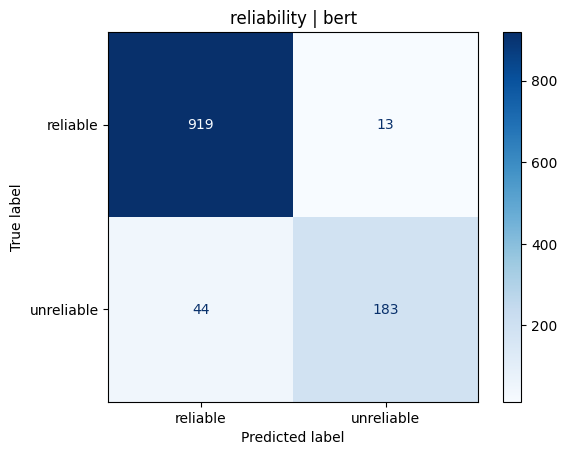

[load] reliability_roberta — using saved weights


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Map:   0%|          | 0/1159 [00:00<?, ? examples/s]


=== reliability | roberta ===
              precision    recall  f1-score   support

    reliable       0.97      0.99      0.98       932
  unreliable       0.97      0.88      0.92       227

    accuracy                           0.97      1159
   macro avg       0.97      0.94      0.95      1159
weighted avg       0.97      0.97      0.97      1159



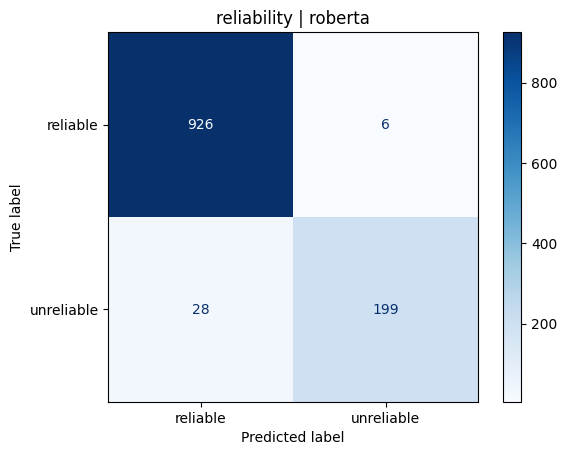

[load] reliability_pubmedbert — using saved weights


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Map:   0%|          | 0/1159 [00:00<?, ? examples/s]


=== reliability | pubmedbert ===
              precision    recall  f1-score   support

    reliable       0.95      0.99      0.97       932
  unreliable       0.97      0.78      0.87       227

    accuracy                           0.95      1159
   macro avg       0.96      0.89      0.92      1159
weighted avg       0.95      0.95      0.95      1159



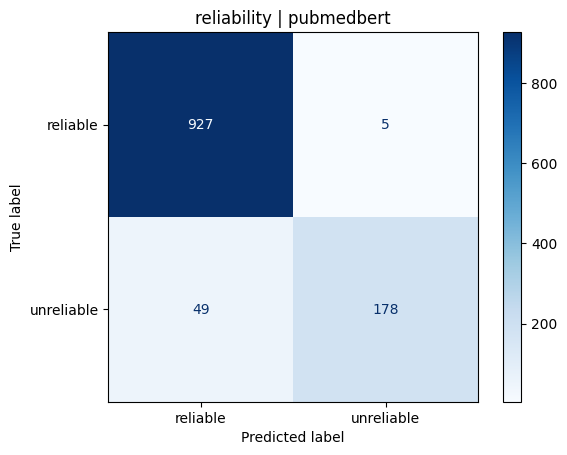


TASK: originality
official split | train/val/test = 24924/2778/6954 | class weights = [3.0, 0.6000000238418579]

=== originality | TFIDF+LogReg ===
              precision    recall  f1-score   support

       human       0.97      0.99      0.98      1159
          ai       1.00      0.99      1.00      5795

    accuracy                           0.99      6954
   macro avg       0.98      0.99      0.99      6954
weighted avg       0.99      0.99      0.99      6954


=== originality | TFIDF+LinearSVM ===
              precision    recall  f1-score   support

       human       0.99      1.00      0.99      1159
          ai       1.00      1.00      1.00      5795

    accuracy                           1.00      6954
   macro avg       0.99      1.00      1.00      6954
weighted avg       1.00      1.00      1.00      6954

[load] originality_bert — using saved weights


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Map:   0%|          | 0/6954 [00:00<?, ? examples/s]


=== originality | bert ===
              precision    recall  f1-score   support

       human       1.00      0.98      0.99      1159
          ai       1.00      1.00      1.00      5795

    accuracy                           1.00      6954
   macro avg       1.00      0.99      0.99      6954
weighted avg       1.00      1.00      1.00      6954



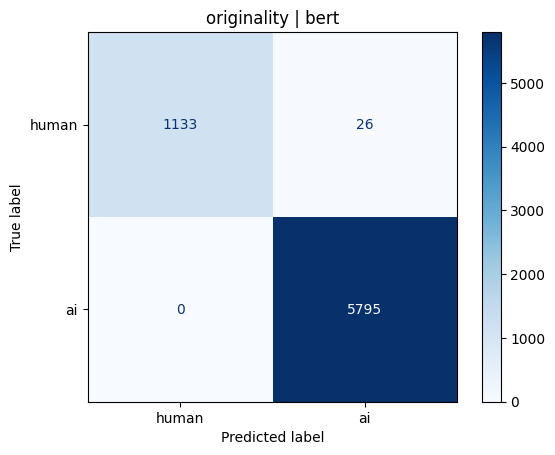

[load] originality_roberta — using saved weights


Loading weights:   0%|          | 0/201 [00:02<?, ?it/s]

Map:   0%|          | 0/6954 [00:00<?, ? examples/s]


=== originality | roberta ===
              precision    recall  f1-score   support

       human       1.00      1.00      1.00      1159
          ai       1.00      1.00      1.00      5795

    accuracy                           1.00      6954
   macro avg       1.00      1.00      1.00      6954
weighted avg       1.00      1.00      1.00      6954



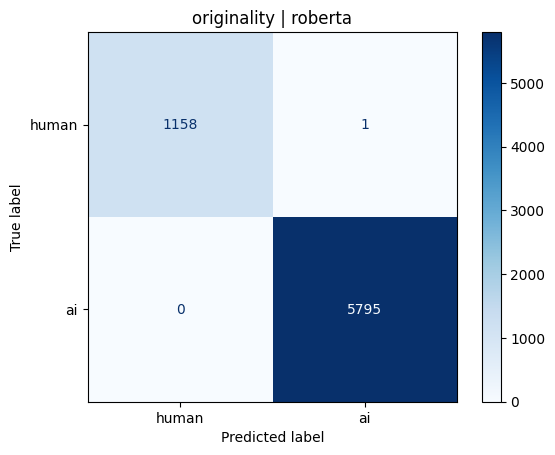

[load] originality_pubmedbert — using saved weights


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Map:   0%|          | 0/6954 [00:00<?, ? examples/s]


=== originality | pubmedbert ===
              precision    recall  f1-score   support

       human       1.00      1.00      1.00      1159
          ai       1.00      1.00      1.00      5795

    accuracy                           1.00      6954
   macro avg       1.00      1.00      1.00      6954
weighted avg       1.00      1.00      1.00      6954



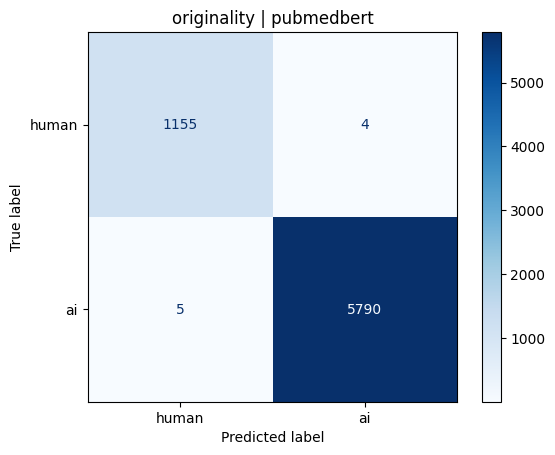


ALL MODELS DONE


In [6]:
RESULTS, PREDS, DATA = [], {}, {}
for task in TASKS:
    print("\n" + "=" * 70 + f"\nTASK: {task}\n" + "=" * 70)
    work, label_names, label2id = make_task_frame(df, task)
    train_df, val_df, test_df = split_frame(work)            # official train/val/test
    cw = class_weights_for(train_df)
    DATA[task] = dict(train=train_df, val=val_df, test=test_df,
                      label_names=label_names, label2id=label2id, class_weights=cw)
    print(f"official split | train/val/test = {len(train_df)}/{len(val_df)}/{len(test_df)} "
          f"| class weights = {cw.tolist()}")

    run_baselines(task, train_df, test_df, label_names)
    for key, name in MODELS.items():
        yt, yp = train_or_load(task, key, name, train_df, val_df, test_df,
                               label_names, label2id, cw,
                               retrain=RETRAIN_IF_EXISTS, save=SAVE_MODELS, epochs=EPOCHS)
        log_result(task, key, yt, yp, label_names, plot=True)

print("\nALL MODELS DONE")


## 6. Combined results table

In [7]:
results_df = (
    pd.DataFrame(RESULTS)
    .drop_duplicates(subset=["task", "model"], keep="last")
    .sort_values(["task", "macro_f1"], ascending=[True, False])
    .reset_index(drop=True)
)

num_cols = ["accuracy", "precision", "recall", "weighted_f1", "macro_f1"]
results_display = results_df.copy()
results_display[num_cols] = results_display[num_cols].round(3)

# Verify that all five models are present for each task.
print(results_df.groupby("task")["model"].nunique().to_dict())

display(results_display)

{'originality': 5, 'reliability': 5}


,task,model,accuracy,precision,recall,weighted_f1,macro_f1
0,originality,roberta,1.000,1.000,1.000,1.000,1.000
1,originality,pubmedbert,0.999,0.999,0.999,0.999,0.998
2,originality,TFIDF+LinearSVM,0.998,0.998,0.998,0.998,0.996
3,originality,bert,0.996,0.996,0.996,0.996,0.993
4,originality,TFIDF+LogReg,0.994,0.994,0.994,0.994,0.988
5,reliability,roberta,0.971,0.971,0.971,0.970,0.952
6,reliability,pubmedbert,0.953,0.954,0.953,0.951,0.920
7,reliability,bert,0.951,0.950,0.951,0.949,0.918
8,reliability,TFIDF+LinearSVM,0.940,0.938,0.940,0.939,0.901
9,reliability,TFIDF+LogReg,0.903,0.909,0.903,0.906,0.854


## 7. Statistical Significance: McNemar's Test

McNemar's test is used to compare paired predictions from two models evaluated on the same test articles. To keep the analysis focused and limit multiple testing, RoBERTa is compared with each of the four alternative models separately within each task. The following cell performs these pairwise comparisons and applies Holm correction to the resulting p-values. Holm-adjusted p-values below 0.05 are treated as statistically significant.

In [8]:
# Compare RoBERTa with each alternative model using McNemar's test.

COMPARISON_MODELS = [
    "TFIDF+LogReg",
    "TFIDF+LinearSVM",
    "bert",
    "pubmedbert",
]

def holm_adjust(p_values):
    """Return Holm-adjusted p-values in the original order."""
    p_values = np.asarray(p_values, dtype=float)
    n_tests = len(p_values)

    if n_tests == 0:
        return np.asarray([], dtype=float)

    order = np.argsort(p_values)
    sorted_p = p_values[order]

    adjusted_sorted = np.maximum.accumulate(
        (n_tests - np.arange(n_tests)) * sorted_p
    )
    adjusted_sorted = np.clip(adjusted_sorted, 0, 1)

    adjusted = np.empty(n_tests, dtype=float)
    adjusted[order] = adjusted_sorted
    return adjusted


mcnemar_rows = []

for task in TASKS:
    if (task, "roberta") not in PREDS:
        print(f"[{task}] RoBERTa predictions unavailable; skipping.")
        continue

    task_rows = []
    y_true_roberta, roberta_predictions = PREDS[(task, "roberta")]

    for comparison_model in COMPARISON_MODELS:
        if (task, comparison_model) not in PREDS:
            continue

        y_true_other, other_predictions = PREDS[(task, comparison_model)]

        if not np.array_equal(y_true_roberta, y_true_other):
            raise ValueError(
                f"Prediction targets do not align for {task}: "
                f"roberta versus {comparison_model}."
            )

        # n01: RoBERTa only correct; n10: comparison model only correct.
        n01, n10, statistic, raw_p, method = mcnemar(
            y_true_roberta,
            roberta_predictions,
            other_predictions,
        )

        task_rows.append({
            "task": task,
            "comparison": f"roberta vs {comparison_model}",
            "comparison_model": comparison_model,
            "roberta_only_correct": n01,
            "comparison_only_correct": n10,
            "statistic": statistic,
            "raw_p": raw_p,
            "method": method,
        })

    adjusted_p_values = holm_adjust([row["raw_p"] for row in task_rows])

    for row, adjusted_p in zip(task_rows, adjusted_p_values):
        row["holm_p"] = float(adjusted_p)
        row["significant_after_holm"] = bool(adjusted_p < 0.05)

    mcnemar_rows.extend(task_rows)

    print(f"\n[{task}] RoBERTa comparisons with Holm correction:")

    if task_rows:
        task_table = pd.DataFrame(task_rows)
        display(
            task_table[
                [
                    "comparison",
                    "roberta_only_correct",
                    "comparison_only_correct",
                    "statistic",
                    "raw_p",
                    "holm_p",
                    "method",
                    "significant_after_holm",
                ]
            ].round({"statistic": 3, "raw_p": 6, "holm_p": 6})
        )
    else:
        print("No comparison predictions available.")

mcnemar_results_df = pd.DataFrame(mcnemar_rows)


[reliability] RoBERTa comparisons with Holm correction:


,comparison,roberta_only_correct,comparison_only_correct,statistic,raw_p,holm_p,method,significant_after_holm
0,roberta vs TFIDF+LogReg,93,15,54.898,0.000000,0.000000,chi-square (cc),True
1,roberta vs TFIDF+LinearSVM,54,18,17.014,0.000037,0.000111,chi-square (cc),True
2,roberta vs bert,31,8,12.410,0.000427,0.000854,chi-square (cc),True
3,roberta vs pubmedbert,28,8,10.028,0.001542,0.001542,chi-square (cc),True



[originality] RoBERTa comparisons with Holm correction:


,comparison,roberta_only_correct,comparison_only_correct,statistic,raw_p,holm_p,method,significant_after_holm
0,roberta vs TFIDF+LogReg,45,1,40.196,0.000000,0.000000,chi-square (cc),True
1,roberta vs TFIDF+LinearSVM,17,1,NaN,0.000145,0.000290,exact binomial,True
2,roberta vs bert,25,0,23.040,0.000002,0.000005,chi-square (cc),True
3,roberta vs pubmedbert,9,1,NaN,0.021484,0.021484,exact binomial,True


## 8. Leakage and Dataset Composition Checks

Before the robustness analyses, the following checks verify that no article identifiers overlap between the training and test sets and summarise the distribution of AI-generated training articles across generators. The generator counts provide context for the later cross-generator evaluation.

In [9]:
for task in TASKS:
    d = DATA[task]

    # Verify that no article appears in both training and test sets.
    overlap = set(d["train"]["uid"]) & set(d["test"]["uid"])
    print(
        f"\n[{task}] train/test article (uid) overlap: "
        f"{len(overlap)} (0 = no contamination)"
    )

# Summarise AI-generated training articles by generator.
print("\nAI text per generator (originality train):")
print(
    DATA["originality"]["train"]
    .query("origin == 'ai'")["generator"]
    .value_counts()
    .to_string()
)


[reliability] train/test article (uid) overlap: 0 (0 = no contamination)

[originality] train/test article (uid) overlap: 0 (0 = no contamination)

AI text per generator (originality train):
generator
llama3.1    4154
qwen2.5     4154
chatglm4    4154
gemma2      4154
mistral     4154


## 9. Reliability Robustness Under Authorship Shift

The previously trained reliability RoBERTa model is evaluated without retraining under three test conditions:

1. **Human originals:** the official human-written reliability test set.
2. **Matched AI rewrites:** one reproducibly selected AI-generated version for each test article.
3. **Mixed human–AI set:** one version of each article, with approximately half represented by the human original and half by an AI-generated version.

Only article identifiers available in both authorship conditions are retained. One AI version per article is selected using the fixed project seed. For the mixed condition, human and AI versions are allocated separately within each reliability class so that authorship is not confounded with the reliability label.


In [11]:
ROBERTA_DIR = os.path.join(OUTPUT_DIR, "reliability_roberta")
LABEL_NAMES = ["reliable", "unreliable"]
LABEL2ID = {"reliable": 0, "unreliable": 1}

if not os.path.isfile(os.path.join(ROBERTA_DIR, "config.json")):
    raise FileNotFoundError(
        f"Saved reliability RoBERTa not found at: {ROBERTA_DIR}"
    )

# Load the previously trained human-only reliability model.
robustness_tokenizer = AutoTokenizer.from_pretrained(ROBERTA_DIR)
robustness_model = AutoModelForSequenceClassification.from_pretrained(
    ROBERTA_DIR
)

eval_trainer = Trainer(
    model=robustness_model,
    args=TrainingArguments(
        output_dir=os.path.join(OUTPUT_DIR, "human_to_ai_evaluation"),
        per_device_eval_batch_size=BATCH_SIZE,
        report_to="none",
    ),
    data_collator=DataCollatorWithPadding(robustness_tokenizer),
)


# Build matched human and AI test sets.
human_test = DATA["reliability"]["test"].copy()

ai_test_all = df[
    (df["split"] == "test") &
    (df["origin"] == "ai")
].copy()

ai_test_all["label"] = ai_test_all["reliability"].map(LABEL2ID)
ai_test_all = ai_test_all.reset_index(drop=True)

common_uids = set(human_test["uid"]) & set(ai_test_all["uid"])

if (
    len(common_uids) != human_test["uid"].nunique()
    or len(common_uids) != ai_test_all["uid"].nunique()
):
    print("Warning: unmatched test articles were removed.")

human_test = (
    human_test[human_test["uid"].isin(common_uids)]
    .reset_index(drop=True)
)

ai_test_all = (
    ai_test_all[ai_test_all["uid"].isin(common_uids)]
    .reset_index(drop=True)
)


# Select one reproducible AI rewrite per article.
rng = np.random.default_rng(SEED)

ai_test_matched = ai_test_all.copy()
ai_test_matched["_random_order"] = rng.random(len(ai_test_matched))

ai_test_matched = (
    ai_test_matched
    .sort_values(["uid", "_random_order"])
    .drop_duplicates(subset="uid", keep="first")
    .drop(columns="_random_order")
    .reset_index(drop=True)
)

assert ai_test_matched["uid"].nunique() == human_test["uid"].nunique()
assert set(ai_test_matched["uid"]) == set(human_test["uid"])


# Build the reliability-stratified mixed-authorship test set.
mixed_parts = []
mixed_rng = np.random.default_rng(SEED)

for label_value in sorted(human_test["label"].unique()):
    label_uids = (
        human_test.loc[
            human_test["label"] == label_value,
            "uid",
        ]
        .to_numpy()
        .copy()
    )

    mixed_rng.shuffle(label_uids)

    split_point = len(label_uids) // 2
    human_uids = set(label_uids[:split_point])
    ai_uids = set(label_uids[split_point:])

    mixed_parts.extend([
        human_test[
            human_test["uid"].isin(human_uids)
        ].copy(),
        ai_test_matched[
            ai_test_matched["uid"].isin(ai_uids)
        ].copy(),
    ])

mixed_test = (
    pd.concat(mixed_parts, ignore_index=True)
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

assert mixed_test["uid"].nunique() == len(mixed_test)
assert set(mixed_test["uid"]) == set(human_test["uid"])

print(f"Matched test articles: {len(human_test)}")
print("\nSelected AI generators:")
print(ai_test_matched["generator"].value_counts())
print("\nMixed authorship distribution:")
print(mixed_test["origin"].value_counts())


def evaluate_authorship_condition(condition, test_frame):
    """Evaluate the saved human-trained RoBERTa on one test condition."""
    output = eval_trainer.predict(
        _make_ds(test_frame, robustness_tokenizer)
    )

    y_true = output.label_ids
    y_pred = output.predictions.argmax(axis=-1)

    print(f"\n{condition}")
    print(
        classification_report(
            y_true,
            y_pred,
            target_names=LABEL_NAMES,
            zero_division=0,
        )
    )

    return {
        "test_condition": condition,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
    }


robustness_results = pd.DataFrame([
    evaluate_authorship_condition(
        "Human originals",
        human_test,
    ),
    evaluate_authorship_condition(
        "Matched AI rewrites",
        ai_test_matched,
    ),
    evaluate_authorship_condition(
        "Mixed human–AI set",
        mixed_test,
    ),
])

display(robustness_results.round(3))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Matched test articles: 1159

Selected AI generators:
generator
mistral     242
gemma2      238
chatglm4    234
llama3.1    225
qwen2.5     220
Name: count, dtype: int64

Mixed authorship distribution:
origin
ai       580
human    579
Name: count, dtype: int64


Map:   0%|          | 0/1159 [00:00<?, ? examples/s]


Human originals
              precision    recall  f1-score   support

    reliable       0.97      0.99      0.98       932
  unreliable       0.97      0.88      0.92       227

    accuracy                           0.97      1159
   macro avg       0.97      0.94      0.95      1159
weighted avg       0.97      0.97      0.97      1159



Map:   0%|          | 0/1159 [00:00<?, ? examples/s]


Matched AI rewrites
              precision    recall  f1-score   support

    reliable       0.86      0.77      0.82       932
  unreliable       0.35      0.50      0.41       227

    accuracy                           0.72      1159
   macro avg       0.61      0.64      0.61      1159
weighted avg       0.76      0.72      0.74      1159



Map:   0%|          | 0/1159 [00:00<?, ? examples/s]


Mixed human–AI set
              precision    recall  f1-score   support

    reliable       0.92      0.87      0.90       932
  unreliable       0.57      0.70      0.63       227

    accuracy                           0.84      1159
   macro avg       0.75      0.79      0.76      1159
weighted avg       0.85      0.84      0.84      1159



,test_condition,accuracy,macro_f1
0,Human originals,0.971,0.952
1,Matched AI rewrites,0.720,0.614
2,Mixed human–AI set,0.837,0.761


### 9.1 Paired Error Analysis Under Authorship Shift

A paired analysis compares predictions for each human-written test article with its matched AI rewrite using the same article identifier. Prediction transitions are grouped as correct in both conditions, correct only for the human version, correct only for the AI version, or incorrect in both.

Errors are also separated into false-reliable and false-unreliable predictions according to the MM-Health reliability labels.

In [13]:
ID2LABEL = {
    LABEL2ID["reliable"]: "reliable",
    LABEL2ID["unreliable"]: "unreliable",
}


def predict_reliability_examples(test_frame):
    """Return article-level predictions from the saved reliability RoBERTa."""
    ordered = test_frame.sort_values("uid").reset_index(drop=True)

    output = eval_trainer.predict(
        _make_ds(ordered, robustness_tokenizer)
    )

    logits = (
        output.predictions[0]
        if isinstance(output.predictions, tuple)
        else output.predictions
    )

    y_true = np.asarray(output.label_ids)
    y_pred = np.asarray(logits).argmax(axis=-1)

    if not np.array_equal(y_true, ordered["label"].to_numpy()):
        raise ValueError(
            "Prediction labels are not aligned with dataframe rows."
        )

    return pd.DataFrame({
        "uid": ordered["uid"].to_numpy(),
        "true_id": y_true,
        "true_label": [ID2LABEL[int(x)] for x in y_true],
        "predicted_id": y_pred,
        "correct": y_true == y_pred,
    })


# Obtain paired predictions.
human_predictions = predict_reliability_examples(
    human_test
).rename(
    columns={
        "predicted_id": "human_predicted_id",
        "correct": "human_correct",
    }
)

ai_predictions = predict_reliability_examples(
    ai_test_matched
).rename(
    columns={
        "predicted_id": "ai_predicted_id",
        "correct": "ai_correct",
    }
)

assert human_predictions["uid"].is_unique
assert ai_predictions["uid"].is_unique
assert set(human_predictions["uid"]) == set(ai_predictions["uid"])

paired_predictions = human_predictions.merge(
    ai_predictions[
        ["uid", "ai_predicted_id", "ai_correct"]
    ],
    on="uid",
    validate="one_to_one",
)

assert len(paired_predictions) == len(human_test)
assert len(paired_predictions) == len(ai_test_matched)


# Prediction transitions after AI rewriting.
transition_order = [
    "Correct in both conditions",
    "Human correct, AI incorrect",
    "Human incorrect, AI correct",
    "Incorrect in both conditions",
]

paired_predictions["prediction_transition"] = np.select(
    [
        paired_predictions["human_correct"]
        & paired_predictions["ai_correct"],

        paired_predictions["human_correct"]
        & ~paired_predictions["ai_correct"],

        ~paired_predictions["human_correct"]
        & paired_predictions["ai_correct"],

        ~paired_predictions["human_correct"]
        & ~paired_predictions["ai_correct"],
    ],
    transition_order,
    default="Unclassified",
)

paired_predictions["prediction_transition"] = pd.Categorical(
    paired_predictions["prediction_transition"],
    categories=transition_order,
    ordered=True,
)

transition_summary = (
    paired_predictions["prediction_transition"]
    .value_counts(sort=False)
    .rename_axis("prediction_transition")
    .reset_index(name="n_articles")
)

transition_summary["percentage_of_articles"] = (
    transition_summary["n_articles"]
    .div(len(paired_predictions))
    .mul(100)
    .round(2)
)

print("Paired prediction transitions:")
display(transition_summary)


# Errors by true reliability class.
class_rows = []

for true_label, group in paired_predictions.groupby(
    "true_label",
    sort=False,
):
    n_articles = len(group)

    human_errors = int(
        (~group["human_correct"]).sum()
    )

    ai_errors = int(
        (~group["ai_correct"]).sum()
    )

    new_errors = int(
        (
            group["human_correct"]
            & ~group["ai_correct"]
        ).sum()
    )

    class_rows.append({
        "true_label": true_label,
        "n_articles": n_articles,
        "human_errors": human_errors,
        "human_error_rate": 100 * human_errors / n_articles,
        "ai_errors": ai_errors,
        "ai_error_rate": 100 * ai_errors / n_articles,
        "new_errors_after_rewrite": new_errors,
        "new_error_rate": 100 * new_errors / n_articles,
    })

class_error_summary = pd.DataFrame(class_rows)

rate_columns = [
    "human_error_rate",
    "ai_error_rate",
    "new_error_rate",
]

class_error_summary[rate_columns] = (
    class_error_summary[rate_columns].round(2)
)

print("\nErrors by true reliability class:")
display(class_error_summary)


# Direction of errors on matched AI rewrites.
true_unreliable = (
    paired_predictions["true_id"]
    == LABEL2ID["unreliable"]
)

true_reliable = (
    paired_predictions["true_id"]
    == LABEL2ID["reliable"]
)

false_reliable = (
    true_unreliable
    & (
        paired_predictions["ai_predicted_id"]
        == LABEL2ID["reliable"]
    )
)

false_unreliable = (
    true_reliable
    & (
        paired_predictions["ai_predicted_id"]
        == LABEL2ID["unreliable"]
    )
)

error_direction_summary = pd.DataFrame([
    {
        "error_type": "False reliable",
        "n_errors": int(false_reliable.sum()),
        "true_class_total": int(true_unreliable.sum()),
    },
    {
        "error_type": "False unreliable",
        "n_errors": int(false_unreliable.sum()),
        "true_class_total": int(true_reliable.sum()),
    },
])

error_direction_summary["error_rate_within_true_class"] = (
    error_direction_summary["n_errors"]
    .div(error_direction_summary["true_class_total"])
    .mul(100)
    .round(2)
)

print("\nDirection of errors on matched AI rewrites:")
display(error_direction_summary)

Map:   0%|          | 0/1159 [00:00<?, ? examples/s]

Map:   0%|          | 0/1159 [00:00<?, ? examples/s]

Paired prediction transitions:


,prediction_transition,n_articles,percentage_of_articles
0,Correct in both conditions,822,70.92
1,"Human correct, AI incorrect",303,26.14
2,"Human incorrect, AI correct",13,1.12
3,Incorrect in both conditions,21,1.81



Errors by true reliability class:


,true_label,n_articles,human_errors,human_error_rate,ai_errors,ai_error_rate,new_errors_after_rewrite,new_error_rate
0,reliable,932,6,0.64,210,22.53,208,22.32
1,unreliable,227,28,12.33,114,50.22,95,41.85



Direction of errors on matched AI rewrites:


,error_type,n_errors,true_class_total,error_rate_within_true_class
0,False reliable,114,227,50.22
1,False unreliable,210,932,22.53


#### Interpretation

The main authorship-shift signal is the number of articles that were correct in human-written form but became incorrect after AI rewriting. Class-level and error-direction summaries show whether these new errors are concentrated in reliable- or unreliable-labelled articles.

These results are descriptive and do not identify which specific textual changes caused the errors.

## 10. Cross-Source Generalisation for Reliability

The reliability classifier is trained on three MM-Health source datasets and evaluated on the held-out fourth source. This tests how well the model transfers to an unseen component dataset rather than relying only on the standard in-distribution split.

In [23]:
# Cross-source generalisation for reliability.

if not RUN_CROSS_SOURCE:
    print("Cross-source evaluation skipped.")

else:
    TASK = "reliability"
    MODEL_KEY = CROSS_MODEL

    work, label_names, label2id = make_task_frame(df, TASK)
    cross_source_results = []

    for held_out_source in sorted(work["source"].dropna().unique()):

        print(f"\nHeld-out source: {held_out_source}")

        development_pool = work[
            work["source"] != held_out_source
        ].copy()

        test_df = (
            work[work["source"] == held_out_source]
            .copy()
            .reset_index(drop=True)
        )

        # UID-grouped validation split from the three training sources.
        train_df, val_df = carve_val(
            development_pool,
            frac=0.15,
            seed=SEED,
        )

        # Verify source separation and absence of article leakage.
        assert held_out_source not in set(train_df["source"])
        assert held_out_source not in set(val_df["source"])
        assert set(test_df["source"]) == {held_out_source}

        assert set(train_df["uid"]).isdisjoint(val_df["uid"])
        assert set(train_df["uid"]).isdisjoint(test_df["uid"])
        assert set(val_df["uid"]).isdisjoint(test_df["uid"])

        if test_df["label"].nunique() < 2 or len(test_df) < 20:
            print("Skipped: insufficient test data.")
            continue

        fold_class_weights = class_weights_for(train_df)

        safe_source = re.sub(
            r"[^A-Za-z0-9_-]+",
            "_",
            str(held_out_source),
        )

        y_true, y_pred = train_or_load(
            task=TASK,
            key=MODEL_KEY,
            model_name=MODELS[MODEL_KEY],
            train_df=train_df,
            val_df=val_df,
            test_df=test_df,
            label_names=label_names,
            label2id=label2id,
            class_weights=fold_class_weights,
            retrain=True,
            save=False,
            epochs=CROSS_EPOCHS,
            seed=SEED,
            save_name=f"cross_source_reliability_{safe_source}",
        )

        accuracy = accuracy_score(y_true, y_pred)
        macro_f1 = f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        )

        print(
            classification_report(
                y_true,
                y_pred,
                target_names=label_names,
                zero_division=0,
            )
        )

        cross_source_results.append({
            "held_out_source": held_out_source,
            "accuracy": accuracy,
            "macro_f1": macro_f1,
        })


    cross_source_reliability_df = (
        pd.DataFrame(cross_source_results)
        .sort_values("macro_f1", ascending=False)
        .reset_index(drop=True)
    )

    print("\nCross-source reliability results:")
    display(cross_source_reliability_df.round(3))


Held-out source: MM-COVID19
[train] cross_source_reliability_MM-COVID19: roberta-base


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

Map:   0%|          | 0/658 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.272144,0.172219,0.948328,0.929507
2,0.163773,0.142895,0.978723,0.968407
3,0.093881,0.140748,0.980243,0.970888


Map:   0%|          | 0/1383 [00:00<?, ? examples/s]

              precision    recall  f1-score   support

    reliable       0.98      0.98      0.98      1221
  unreliable       0.83      0.85      0.84       162

    accuracy                           0.96      1383
   macro avg       0.91      0.91      0.91      1383
weighted avg       0.96      0.96      0.96      1383


Cross-source reliability results:


,held_out_source,accuracy,macro_f1
0,Med-MMHL,0.963,0.941
1,ReCOVery,0.962,0.910
2,MMCoVar,0.950,0.894
3,MM-COVID19,0.827,0.785


## 11. Cross-Generator Generalisation for Originality

The originality classifier is trained using AI-generated articles from four generators and evaluated on the held-out fifth generator, repeating this process for each generator in turn.

This tests how well the classifier transfers to AI-generated text from a generator that was not represented during training. Substantial performance differences across held-out generators may indicate sensitivity to generator-specific characteristics rather than fully generator-independent originality cues.

In [24]:
# Cross-generator generalisation for originality.

CROSS_GEN_SEEDS = {
    "mistral": [42, 43, 44],
}

if not RUN_CROSS_GENERATOR:
    print("Cross-generator evaluation skipped.")

else:
    d = DATA["originality"]
    label_names = d["label_names"]
    label2id = d["label2id"]

    generators = sorted(
        d["train"]
        .query("origin == 'ai'")["generator"]
        .unique()
    )

    def exclude_generator(frame, held_out):
        """Humans plus AI text from all other generators."""
        return frame[
            (frame["origin"] == "human")
            | (frame["generator"] != held_out)
        ].reset_index(drop=True)

    def held_out_test(frame, held_out):
        """Humans plus AI text from the held-out generator."""
        return frame[
            (frame["origin"] == "human")
            | (frame["generator"] == held_out)
        ].reset_index(drop=True)


    cross_generator_results = []

    for held_out in generators:

        train_df = exclude_generator(d["train"], held_out)
        val_df = exclude_generator(d["val"], held_out)
        test_df = held_out_test(d["test"], held_out)

        seeds = CROSS_GEN_SEEDS.get(held_out, [SEED])
        seed_scores = []

        for seed in seeds:
            y_true, y_pred = train_or_load(
                task="originality",
                key=CROSS_MODEL,
                model_name=MODELS[CROSS_MODEL],
                train_df=train_df,
                val_df=val_df,
                test_df=test_df,
                label_names=label_names,
                label2id=label2id,
                class_weights=class_weights_for(train_df),
                retrain=True,
                save=False,
                epochs=CROSS_EPOCHS,
                seed=seed,
                save_name=(
                    f"cross_generator_{held_out}_seed_{seed}"
                ),
            )

            macro_f1 = f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0,
            )

            seed_scores.append(macro_f1)

            print(
                f"Held-out {held_out}, seed {seed}: "
                f"macro-F1 = {macro_f1:.3f}"
            )

        mean_f1 = float(np.mean(seed_scores))
        sd_f1 = (
            float(np.std(seed_scores, ddof=1))
            if len(seed_scores) > 1
            else 0.0
        )

        cross_generator_results.append({
            "held_out_generator": held_out,
            "macro_f1_mean": mean_f1,
            "macro_f1_sd": sd_f1,
        })


    cross_generator_df = pd.DataFrame(
        cross_generator_results
    )

    print("\nCross-generator originality results:")
    display(
        cross_generator_df.round({
            "macro_f1_mean": 3,
            "macro_f1_sd": 3,
        })
    )

[train] cross_generator_chatglm4_seed_42: roberta-base


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/20770 [00:00<?, ? examples/s]

Map:   0%|          | 0/2315 [00:00<?, ? examples/s]

...

Map:   0%|          | 0/2315 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.020529,0.057023,0.997408,0.995931
2,0.021675,0.084167,0.993952,0.990442
3,0.000011,0.026265,0.998704,0.997970


Map:   0%|          | 0/2318 [00:00<?, ? examples/s]

Held-out qwen2.5, seed 42: macro-F1 = 0.996

Cross-generator originality results:


,held_out_generator,macro_f1_mean,macro_f1_sd
0,chatglm4,0.998,0.000
1,gemma2,0.997,0.000
2,llama3.1,0.985,0.000
3,mistral,0.591,0.092
4,qwen2.5,0.996,0.000


## 12. Investigation of the Mistral Cross-Generator Generalisation Failure

Cross-generator evaluation showed strong transfer to four unseen generators but substantially weaker performance when Mistral was held out. To investigate this failure, formatting patterns were compared across human and AI-generated articles, revealing a pronounced imbalance in leading-Markdown usage across generators.

In [14]:
# Detect Markdown headings or bold text at the start of an article.
MD_PAT = r"^\s*(?:#{1,6}\s+|\*\*)"

df["has_leading_markdown"] = (
    df["text"]
    .fillna("")
    .astype(str)
    .str.match(MD_PAT, na=False)
)


# Prevalence by origin.
markdown_by_origin = (
    df.groupby("origin", as_index=False)
    .agg(
        number_of_texts=("has_leading_markdown", "size"),
        number_with_leading_markdown=("has_leading_markdown", "sum"),
        leading_markdown_percentage=(
            "has_leading_markdown",
            lambda x: 100 * x.mean(),
        ),
    )
)

markdown_by_origin["leading_markdown_percentage"] = (
    markdown_by_origin["leading_markdown_percentage"].round(1)
)

print("Leading Markdown prevalence by origin:")
display(markdown_by_origin)


# Prevalence by AI generator.
markdown_by_generator = (
    df[df["origin"] == "ai"]
    .groupby("generator", as_index=False)
    .agg(
        number_of_texts=("has_leading_markdown", "size"),
        number_with_leading_markdown=("has_leading_markdown", "sum"),
        leading_markdown_percentage=(
            "has_leading_markdown",
            lambda x: 100 * x.mean(),
        ),
    )
    .sort_values("leading_markdown_percentage", ascending=False)
    .reset_index(drop=True)
)

markdown_by_generator["leading_markdown_percentage"] = (
    markdown_by_generator["leading_markdown_percentage"].round(1)
)

print("\nLeading Markdown prevalence by AI generator:")
display(markdown_by_generator)

Leading Markdown prevalence by origin:


,origin,number_of_texts,number_with_leading_markdown,leading_markdown_percentage
0,ai,28880,22269,77.1
1,human,5776,2,0.0



Leading Markdown prevalence by AI generator:


,generator,number_of_texts,number_with_leading_markdown,leading_markdown_percentage
0,qwen2.5,5776,5751,99.6
1,gemma2,5776,5608,97.1
2,llama3.1,5776,5604,97.0
3,chatglm4,5776,5298,91.7
4,mistral,5776,8,0.1


In [15]:
# Leading-Markdown normalisation for the originality task.
MD_PAT = r"^\s*(?:#{1,6}\s+|\*\*)"


def strip_leading_markdown(text):
    """Remove leading Markdown heading or bold-title formatting."""
    text = "" if pd.isna(text) else str(text)

    text = re.sub(r"^\s*#{1,6}\s+", "", text, count=1)
    text = re.sub(r"^\s*\*\*([^\n]*?)\*\*", r"\1", text, count=1)
    text = re.sub(r"^\s*\*\*", "", text, count=1)

    return text.strip()


# Create the Markdown-normalised dataset.
df_md = df.copy()
df_md["text"] = df_md["text"].apply(strip_leading_markdown)
df_md["n_words"] = df_md["text"].str.split().str.len()


# Verify that the targeted leading Markdown was removed.
df_md["has_leading_markdown_after"] = (
    df_md["text"]
    .fillna("")
    .astype(str)
    .str.match(MD_PAT, na=False)
)

print("Leading Markdown rate after normalisation:")
print(
    df_md.groupby("origin")["has_leading_markdown_after"]
    .mean()
    .round(4)
)


# Rebuild the originality task using normalised text.
work_md, LN_MD, L2I_MD = make_task_frame(
    df_md,
    "originality",
)

TR_MD, VA_MD, TE_MD = split_frame(work_md)

print(
    f"\nOriginality splits: "
    f"train={len(TR_MD)}, "
    f"validation={len(VA_MD)}, "
    f"test={len(TE_MD)}"
)

Leading Markdown rate after normalisation:
origin
ai       0.0
human    0.0
Name: has_leading_markdown_after, dtype: float64

Originality splits: train=24924, validation=2778, test=6954


In [16]:
# STANDARD ORIGINALITY AFTER LEADING MARKDOWN NORMALISATION
standard_md_y_true, standard_md_y_pred = train_or_load(
    task="originality_leadingmd_removed",
    key="roberta",
    model_name=MODELS["roberta"],
    train_df=TR_MD,
    val_df=VA_MD,
    test_df=TE_MD,
    label_names=LN_MD,
    label2id=L2I_MD,
    class_weights=class_weights_for(TR_MD),
    retrain=RETRAIN_IF_EXISTS,
    save=SAVE_MODELS,
    epochs=EPOCHS,
    save_name="originality_leadingmd_removed_roberta",
)

standard_md_macro_f1 = f1_score(
    standard_md_y_true,
    standard_md_y_pred,
    average="macro",
    zero_division=0,
)

raw_originality_f1 = results_df.loc[
    (results_df["task"] == "originality")
    & (results_df["model"] == "roberta"),
    "macro_f1",
].iloc[0]

print(f"Raw-text macro-F1:                 {raw_originality_f1:.3f}")
print(f"Leading-Markdown-removed macro-F1: {standard_md_macro_f1:.3f}")
print(
    f"Change:                            "
    f"{standard_md_macro_f1 - raw_originality_f1:+.3f}"
)

[load] originality_leadingmd_removed_roberta — using saved weights


Loading weights:   0%|          | 0/201 [00:01<?, ?it/s]

Map:   0%|          | 0/6954 [00:00<?, ? examples/s]

Raw-text macro-F1:                 1.000
Leading-Markdown-removed macro-F1: 0.999
Change:                            -0.001


In [25]:
# Held-out Mistral after leading-Markdown normalisation.

HELD_GENERATOR = "mistral"
MISTRAL_SEEDS = [42, 43, 44]

# Humans + four non-Mistral generators for training/validation.
mistral_train = TR_MD[
    (TR_MD["origin"] == "human")
    | (TR_MD["generator"] != HELD_GENERATOR)
].reset_index(drop=True)

mistral_val = VA_MD[
    (VA_MD["origin"] == "human")
    | (VA_MD["generator"] != HELD_GENERATOR)
].reset_index(drop=True)

# Humans + unseen Mistral articles for testing.
mistral_test = TE_MD[
    (TE_MD["origin"] == "human")
    | (TE_MD["generator"] == HELD_GENERATOR)
].reset_index(drop=True)

# Verify that Mistral is excluded from training and validation.
assert not (
    mistral_train.query("origin == 'ai'")["generator"]
    == HELD_GENERATOR
).any()

assert not (
    mistral_val.query("origin == 'ai'")["generator"]
    == HELD_GENERATOR
).any()

assert (
    mistral_test.query("origin == 'ai'")["generator"]
    == HELD_GENERATOR
).all()


mistral_class_weights = class_weights_for(mistral_train)
mistral_md_f1s = []

for seed in MISTRAL_SEEDS:
    y_true, y_pred = train_or_load(
        task="originality_leadingmd_removed_xgen",
        key="roberta",
        model_name=MODELS["roberta"],
        train_df=mistral_train,
        val_df=mistral_val,
        test_df=mistral_test,
        label_names=LN_MD,
        label2id=L2I_MD,
        class_weights=mistral_class_weights,
        retrain=True,
        save=False,
        epochs=CROSS_EPOCHS,
        seed=seed,
        save_name=(
            f"originality_leadingmd_removed_"
            f"xgen_mistral_seed_{seed}"
        ),
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0,
    )

    mistral_md_f1s.append(macro_f1)

    print(
        f"Held-out Mistral, seed {seed}: "
        f"macro-F1 = {macro_f1:.3f}"
    )


mistral_md_mean = float(np.mean(mistral_md_f1s))
mistral_md_std = float(np.std(mistral_md_f1s, ddof=1))

# Raw-text reference from Section 11.
raw_mistral = cross_generator_df[
    cross_generator_df["held_out_generator"] == HELD_GENERATOR
].iloc[0]

raw_mistral_mean = float(raw_mistral["macro_f1_mean"])
raw_mistral_sd = float(raw_mistral["macro_f1_sd"])

print("\nHeld-out Mistral comparison:")
print(
    f"Raw text:                 "
    f"{raw_mistral_mean:.3f} ± {raw_mistral_sd:.3f}"
)
print(
    f"Leading Markdown removed: "
    f"{mistral_md_mean:.3f} ± {mistral_md_std:.3f}"
)
print(
    f"Change in mean macro-F1:  "
    f"{mistral_md_mean - raw_mistral_mean:+.3f}"
)

[train] originality_leadingmd_removed_xgen_mistral_seed_42: roberta-base


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/20770 [00:00<?, ? examples/s]

Map:   0%|          | 0/2315 [00:00<?, ? examples/s]

...

Map:   0%|          | 0/20770 [00:00<?, ? examples/s]

Map:   0%|          | 0/2315 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.003702,0.000041,1.000000,1.000000
2,0.000022,0.000009,1.000000,1.000000
3,0.000010,0.000007,1.000000,1.000000


Map:   0%|          | 0/2318 [00:00<?, ? examples/s]

Held-out Mistral, seed 44: macro-F1 = 0.967

Held-out Mistral comparison:
Raw text:                 0.591 ± 0.092
Leading Markdown removed: 0.984 ± 0.015
Change in mean macro-F1:  +0.393


## 13. Residual Originality Signals After Markdown Normalisation

Removing leading Markdown had little effect on the standard originality benchmark, with RoBERTa macro-F1 decreasing from approximately 1.000 to 0.999. In contrast, held-out Mistral performance increased from 0.591 ± 0.092 to 0.984 ± 0.015, an improvement of 0.393 macro-F1.

This suggests that leading Markdown was an important generator-specific shortcut affecting cross-generator generalisation, but it did not fully explain the near-ceiling in-distribution originality performance.

The remaining signal is examined using four analyses:

1. A length-only Logistic Regression baseline.
2. A paired stylometric comparison between each human article and the mean of its five AI rewrites with the same UID.
3. A style-only Logistic Regression classifier using interpretable writing-style features.
4. A Markdown-normalised TF-IDF Logistic Regression classifier using words and bigrams.

These analyses identify predictive associations within MM-Health and should not be interpreted as universal characteristics of human or AI writing.

In [17]:
# LENGTH-ONLY BASELINE — LEADING-MARKDOWN-NORMALISED ORIGINALITY
X_train = TR_MD[["n_words"]]
y_train = TR_MD["label"].to_numpy()

X_test = TE_MD[["n_words"]]
y_test = TE_MD["label"].to_numpy()

length_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=SEED,
)

length_model.fit(X_train, y_train)
y_pred = length_model.predict(X_test)

length_macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0,
)

print(f"Length-only macro-F1: {length_macro_f1:.3f}\n")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=LN_MD,
        zero_division=0,
    )
)


# Median article length by split and origin.
length_summary = (
    pd.concat([
        TR_MD.assign(dataset_split="train"),
        TE_MD.assign(dataset_split="test"),
    ])
    .groupby(["dataset_split", "origin"])["n_words"]
    .median()
    .rename("median_words")
    .to_frame()
    .round(1)
)

print("Median article length:")
display(length_summary)


# Approximate word-count decision boundary.
coefficient = length_model.coef_[0, 0]
word_threshold = -length_model.intercept_[0] / coefficient
ai_direction = "above" if coefficient > 0 else "below"

print(f"Approximate decision boundary: {word_threshold:.0f} words")
print(f"The model tends to predict AI {ai_direction} this boundary.")

Length-only macro-F1: 0.631

              precision    recall  f1-score   support

       human       0.34      0.59      0.43      1159
          ai       0.90      0.77      0.83      5795

    accuracy                           0.74      6954
   macro avg       0.62      0.68      0.63      6954
weighted avg       0.81      0.74      0.76      6954

Median article length:


median_words
dataset_split origin              
test          ai             472.0
              human          652.0
train         ai             476.0
              human          648.5

Approximate decision boundary: 568 words
The model tends to predict AI below this boundary.


Matched article groups: 1159
Significant after Benjamini–Hochberg correction: 17 of 19


,feature_label,paired_cohen_dz,pct_ai_higher,fdr_q
0,Average word length,2.1363,98.4469,0.0000
1,Sentence-length variation,-0.8513,13.3736,0.0000
2,Stopwords per 100 words,-0.6966,17.6877,0.0000
3,Digit-containing tokens per 100 words,-0.4533,24.6764,0.0000
4,Number of words,-0.4103,29.9396,0.0000
5,Number of sentences,-0.3947,29.0768,0.0000
6,Commas per 100 words,-0.3754,29.0768,0.0000
7,Second-person pronouns per 100 words,-0.3260,14.4090,0.0000
8,First-person pronouns per 100 words,-0.3007,37.5324,0.0000
9,Colons per 100 words,0.2747,79.4651,0.0000


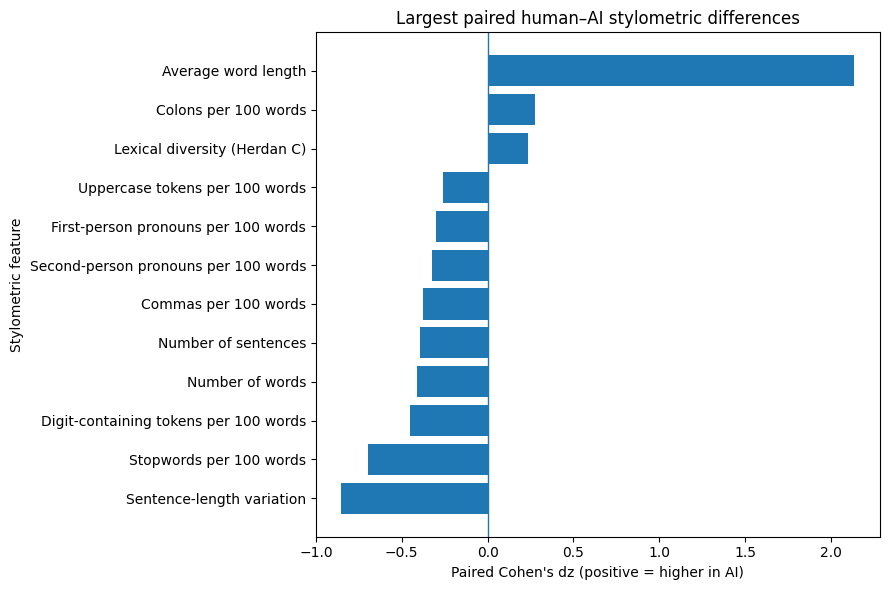

In [19]:
# Paired stylometric analysis on the Markdown-normalised originality test set.
WORD_PATTERN = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")
DIGIT_TOKEN_PATTERN = re.compile(r"\b\w*\d\w*\b")
SENTENCE_SPLIT_PATTERN = re.compile(r"(?<=[.!?])\s+")

FIRST_PERSON_PRONOUNS = {
    "i", "me", "my", "mine", "myself",
    "we", "us", "our", "ours", "ourselves",
}
SECOND_PERSON_PRONOUNS = {
    "you", "your", "yours", "yourself", "yourselves",
}
MODAL_VERBS = {
    "can", "could", "may", "might", "must",
    "shall", "should", "will", "would",
}


def rate_per_100(count, n_words):
    return 100 * count / n_words if n_words else 0.0


def extract_stylometric_features(text):
    """Extract structural and writing-style features from one article."""
    text = clean_text(text)

    words = WORD_PATTERN.findall(text)
    lower_words = [word.lower() for word in words]
    n_words = len(words)

    sentences = [
        sentence
        for sentence in SENTENCE_SPLIT_PATTERN.split(text)
        if WORD_PATTERN.search(sentence)
    ]
    sentence_lengths = [
        len(WORD_PATTERN.findall(sentence))
        for sentence in sentences
    ]

    if n_words and not sentence_lengths:
        sentence_lengths = [n_words]

    n_sentences = len(sentence_lengths)
    n_unique = len(set(lower_words))

    herdan_c = (
        np.log(n_unique) / np.log(n_words)
        if n_words > 1 and n_unique > 0
        else 0.0
    )

    stopwords = sum(w in ENGLISH_STOP_WORDS for w in lower_words)
    first_person = sum(w in FIRST_PERSON_PRONOUNS for w in lower_words)
    second_person = sum(w in SECOND_PERSON_PRONOUNS for w in lower_words)
    modals = sum(w in MODAL_VERBS for w in lower_words)

    digit_tokens = len(DIGIT_TOKEN_PATTERN.findall(text))
    uppercase_tokens = sum(
        len(w) > 1 and w.isupper()
        for w in words
    )

    quote_marks = sum(text.count(mark) for mark in ('"', "“", "”"))
    parentheses = text.count("(") + text.count(")")

    return {
        "n_words": n_words,
        "n_sentences": n_sentences,
        "avg_sentence_words": (
            float(np.mean(sentence_lengths))
            if sentence_lengths else 0.0
        ),
        "sentence_length_sd": (
            float(np.std(sentence_lengths, ddof=0))
            if sentence_lengths else 0.0
        ),
        "avg_word_length": (
            float(np.mean([len(w) for w in words]))
            if words else 0.0
        ),
        "herdan_c": float(herdan_c),
        "stopword_rate_100": rate_per_100(stopwords, n_words),
        "first_person_rate_100": rate_per_100(first_person, n_words),
        "second_person_rate_100": rate_per_100(second_person, n_words),
        "modal_rate_100": rate_per_100(modals, n_words),
        "digit_token_rate_100": rate_per_100(digit_tokens, n_words),
        "comma_rate_100": rate_per_100(text.count(","), n_words),
        "semicolon_rate_100": rate_per_100(text.count(";"), n_words),
        "colon_rate_100": rate_per_100(text.count(":"), n_words),
        "question_rate_100": rate_per_100(text.count("?"), n_words),
        "exclamation_rate_100": rate_per_100(text.count("!"), n_words),
        "quote_mark_rate_100": rate_per_100(quote_marks, n_words),
        "parenthesis_rate_100": rate_per_100(parentheses, n_words),
        "uppercase_token_rate_100": rate_per_100(
            uppercase_tokens, n_words
        ),
    }


def add_stylometric_features(frame):
    """Add stylometric features without duplicating existing columns."""
    base = frame.copy().reset_index(drop=True)

    features = pd.DataFrame(
        base["text"]
        .apply(extract_stylometric_features)
        .tolist()
    )

    features = features.drop(
        columns=features.columns.intersection(base.columns),
        errors="ignore",
    )

    combined = pd.concat([base, features], axis=1)

    if combined.columns.duplicated().any():
        raise ValueError("Duplicate columns remain after feature extraction.")

    return combined


FEATURE_LABELS = {
    "n_words": "Number of words",
    "n_sentences": "Number of sentences",
    "avg_sentence_words": "Average sentence length",
    "sentence_length_sd": "Sentence-length variation",
    "avg_word_length": "Average word length",
    "herdan_c": "Lexical diversity (Herdan C)",
    "stopword_rate_100": "Stopwords per 100 words",
    "first_person_rate_100": "First-person pronouns per 100 words",
    "second_person_rate_100": "Second-person pronouns per 100 words",
    "modal_rate_100": "Modal verbs per 100 words",
    "digit_token_rate_100": "Digit-containing tokens per 100 words",
    "comma_rate_100": "Commas per 100 words",
    "semicolon_rate_100": "Semicolons per 100 words",
    "colon_rate_100": "Colons per 100 words",
    "question_rate_100": "Question marks per 100 words",
    "exclamation_rate_100": "Exclamation marks per 100 words",
    "quote_mark_rate_100": "Quotation marks per 100 words",
    "parenthesis_rate_100": "Parentheses per 100 words",
    "uppercase_token_rate_100": "Uppercase tokens per 100 words",
}

PAIR_FEATURES = list(FEATURE_LABELS)


# Extract features and retain complete 1-human/5-AI article groups.
paired_test_features = add_stylometric_features(TE_MD)

human_counts = (
    paired_test_features.query("origin == 'human'")
    .groupby("uid")
    .size()
)
ai_counts = (
    paired_test_features.query("origin == 'ai'")
    .groupby("uid")
    .size()
)

complete_uids = (
    human_counts.index[human_counts.eq(1)]
    .intersection(ai_counts.index[ai_counts.eq(5)])
)

n_incomplete = (
    paired_test_features["uid"].nunique()
    - len(complete_uids)
)

if n_incomplete:
    print(
        f"Warning: {n_incomplete} incomplete article group(s) excluded."
    )

paired_test_features = paired_test_features[
    paired_test_features["uid"].isin(complete_uids)
].reset_index(drop=True)

human_by_uid = (
    paired_test_features.query("origin == 'human'")
    .set_index("uid")[PAIR_FEATURES]
    .sort_index()
)

ai_mean_by_uid = (
    paired_test_features.query("origin == 'ai'")
    .groupby("uid")[PAIR_FEATURES]
    .mean()
    .sort_index()
)

assert human_by_uid.index.equals(ai_mean_by_uid.index)

print("Matched article groups:", len(human_by_uid))


# Benjamini–Hochberg correction.
def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=float)
    n = len(p_values)
    order = np.argsort(p_values)

    adjusted = (
        p_values[order]
        * n
        / np.arange(1, n + 1)
    )
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)

    result = np.empty(n)
    result[order] = adjusted
    return result


# Paired feature comparisons.
paired_results = []

for feature in PAIR_FEATURES:
    human_values = human_by_uid[feature].to_numpy(dtype=float)
    ai_values = ai_mean_by_uid[feature].to_numpy(dtype=float)

    differences = ai_values - human_values
    sd = differences.std(ddof=1)

    dz = differences.mean() / sd if sd > 0 else 0.0

    if np.any(differences != 0):
        try:
            p_value = wilcoxon(
                differences,
                zero_method="wilcox",
                alternative="two-sided",
            ).pvalue
        except ValueError:
            p_value = 1.0
    else:
        p_value = 1.0

    paired_results.append({
        "feature": feature,
        "feature_label": FEATURE_LABELS[feature],
        "paired_cohen_dz": float(dz),
        "pct_ai_higher": float(100 * np.mean(differences > 0)),
        "wilcoxon_p": float(p_value),
    })


paired_stylometry_summary = pd.DataFrame(paired_results)

paired_stylometry_summary["fdr_q"] = benjamini_hochberg(
    paired_stylometry_summary["wilcoxon_p"]
)

paired_stylometry_summary["absolute_effect_size"] = (
    paired_stylometry_summary["paired_cohen_dz"].abs()
)

paired_stylometry_summary = (
    paired_stylometry_summary
    .sort_values("absolute_effect_size", ascending=False)
    .reset_index(drop=True)
)

print(
    "Significant after Benjamini–Hochberg correction:",
    (paired_stylometry_summary["fdr_q"] < 0.05).sum(),
    f"of {len(paired_stylometry_summary)}",
)

display(
    paired_stylometry_summary[
        [
            "feature_label",
            "paired_cohen_dz",
            "pct_ai_higher",
            "fdr_q",
        ]
    ].round(4)
)


# Plot the 12 largest absolute paired effect sizes.
plot_data = (
    paired_stylometry_summary
    .head(12)
    .sort_values("paired_cohen_dz")
)

plt.figure(figsize=(9, 6))
plt.barh(
    plot_data["feature_label"],
    plot_data["paired_cohen_dz"],
)
plt.axvline(0, linewidth=1)
plt.xlabel("Paired Cohen's dz (positive = higher in AI)")
plt.ylabel("Stylometric feature")
plt.title("Largest paired human–AI stylometric differences")
plt.tight_layout()
plt.show()

Style-only macro-F1: 0.875

              precision    recall  f1-score   support

       human       0.70      0.92      0.80      1159
          ai       0.98      0.92      0.95      5795

    accuracy                           0.92      6954
   macro avg       0.84      0.92      0.88      6954
weighted avg       0.94      0.92      0.93      6954

Style features ranked by coefficient magnitude:


,feature_label,standardised_coefficient,associated_class
0,Average word length,3.1966,AI
1,Sentence-length variation,-1.0707,human
2,Stopwords per 100 words,1.0140,AI
3,Digit-containing tokens per 100 words,-0.7046,human
4,Colons per 100 words,0.5997,AI
5,Uppercase tokens per 100 words,-0.4775,human
6,First-person pronouns per 100 words,0.3231,AI
7,Parentheses per 100 words,-0.3224,human
8,Question marks per 100 words,-0.2492,human
9,Lexical diversity (Herdan C),0.2249,AI


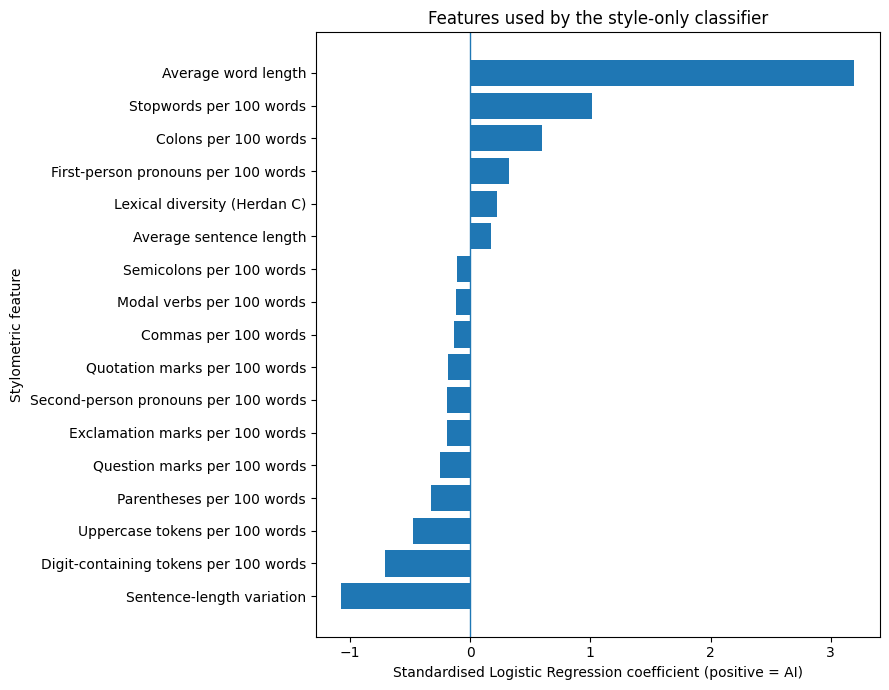

In [20]:
# Style-only originality classifier on Markdown-normalised text.

style_train_df = add_stylometric_features(TR_MD)
style_test_df = add_stylometric_features(TE_MD)

STYLE_ONLY_FEATURES = [
    "avg_sentence_words",
    "sentence_length_sd",
    "avg_word_length",
    "herdan_c",
    "stopword_rate_100",
    "first_person_rate_100",
    "second_person_rate_100",
    "modal_rate_100",
    "digit_token_rate_100",
    "comma_rate_100",
    "semicolon_rate_100",
    "colon_rate_100",
    "question_rate_100",
    "exclamation_rate_100",
    "quote_mark_rate_100",
    "parenthesis_rate_100",
    "uppercase_token_rate_100",
]

X_train_style = style_train_df[STYLE_ONLY_FEATURES]
y_train_style = style_train_df["label"].to_numpy()

X_test_style = style_test_df[STYLE_ONLY_FEATURES]
y_test_style = style_test_df["label"].to_numpy()


style_only_model = Pipeline([
    ("standardise", StandardScaler()),
    (
        "classifier",
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=SEED,
        ),
    ),
])

style_only_model.fit(X_train_style, y_train_style)
style_predictions = style_only_model.predict(X_test_style)

style_macro_f1 = f1_score(
    y_test_style,
    style_predictions,
    average="macro",
    zero_division=0,
)

print(f"Style-only macro-F1: {style_macro_f1:.3f}\n")
print(
    classification_report(
        y_test_style,
        style_predictions,
        target_names=LN_MD,
        zero_division=0,
    )
)


# Standardised Logistic Regression coefficients.
style_coefficient_table = pd.DataFrame({
    "feature_label": [
        FEATURE_LABELS[feature]
        for feature in STYLE_ONLY_FEATURES
    ],
    "standardised_coefficient": (
        style_only_model.named_steps["classifier"].coef_[0]
    ),
})

style_coefficient_table["absolute_coefficient"] = (
    style_coefficient_table["standardised_coefficient"].abs()
)

style_coefficient_table["associated_class"] = np.where(
    style_coefficient_table["standardised_coefficient"] > 0,
    "AI",
    "human",
)

style_coefficient_table = (
    style_coefficient_table
    .sort_values("absolute_coefficient", ascending=False)
    .reset_index(drop=True)
)

print("Style features ranked by coefficient magnitude:")
display(
    style_coefficient_table[
        [
            "feature_label",
            "standardised_coefficient",
            "associated_class",
        ]
    ].round(4)
)


# Plot standardised coefficients.
plot_data = style_coefficient_table.sort_values(
    "standardised_coefficient"
)

plt.figure(figsize=(9, 7))
plt.barh(
    plot_data["feature_label"],
    plot_data["standardised_coefficient"],
)
plt.axvline(0, linewidth=1)
plt.xlabel(
    "Standardised Logistic Regression coefficient "
    "(positive = AI)"
)
plt.ylabel("Stylometric feature")
plt.title("Features used by the style-only classifier")
plt.tight_layout()
plt.show()

In [21]:
# Markdown-normalised TF-IDF originality classifier.

lexical_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=30000,
        ),
    ),
    (
        "classifier",
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=SEED,
        ),
    ),
])

y_train_lexical = TR_MD["label"].to_numpy()
y_test_lexical = TE_MD["label"].to_numpy()

lexical_model.fit(
    TR_MD["text"].fillna(""),
    y_train_lexical,
)

lexical_predictions = lexical_model.predict(
    TE_MD["text"].fillna("")
)

lexical_macro_f1 = f1_score(
    y_test_lexical,
    lexical_predictions,
    average="macro",
    zero_division=0,
)

print(f"TF-IDF lexical macro-F1: {lexical_macro_f1:.3f}\n")
print(
    classification_report(
        y_test_lexical,
        lexical_predictions,
        target_names=LN_MD,
        zero_division=0,
    )
)

TF-IDF lexical macro-F1: 0.988

              precision    recall  f1-score   support

       human       0.97      0.99      0.98      1159
          ai       1.00      0.99      1.00      5795

    accuracy                           0.99      6954
   macro avg       0.98      0.99      0.99      6954
weighted avg       0.99      0.99      0.99      6954



In [22]:
# ================================================================
# FINAL ORIGINALITY EXPLANATION SUMMARY
# ================================================================

originality_explanation_summary = pd.DataFrame(
    [
        {
            "feature_representation": "Length only",
            "information_available": "Article word count",
            "macro_f1": length_macro_f1,
        },
        {
            "feature_representation": "Style only",
            "information_available": (
                "Interpretable stylometric measurements"
            ),
            "macro_f1": style_macro_f1,
        },
        {
            "feature_representation": "TF-IDF lexical",
            "information_available": (
                "Markdown-normalised words and bigrams"
            ),
            "macro_f1": lexical_macro_f1,
        },
        {
            "feature_representation": "RoBERTa",
            "information_available": (
                "First 256 tokens of Markdown-normalised contextual text"
            ),
            "macro_f1": standard_md_macro_f1,
        },
    ]
)

print("Originality feature-representation comparison:")

display(
    originality_explanation_summary.round(3)
)

Originality feature-representation comparison:


,feature_representation,information_available,macro_f1
0,Length only,Article word count,0.631
1,Style only,Interpretable stylometric measurements,0.875
2,TF-IDF lexical,Markdown-normalised words and bigrams,0.988
3,RoBERTa,First 256 tokens of Markdown-normalised contex...,0.999
